<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/susy_field_theory/susyft_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Field Theory* — `susyft_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SUSYFT Ch 2 Figures — Colab Notebook
**Supersymmetric Field Theory · Chapter 2: The Supersymmetry Algebra**

| Figure | Section | Content |
|--------|---------|---------|
| fig01  | §2.1   | Lorentz group: SL(2,C) spinor reps — Weyl, Dirac, Majorana |
| fig02  | §2.2   | SUSY algebra: supercharges, R-symmetry, positive energy |
| fig03  | §2.3   | Massless multiplets: chiral, vector, gravitino, graviton |
| fig04  | §2.3   | Massive multiplets: short vs long, BPS bound illustration |
| fig05  | §2.4   | Extended SUSY: N=2,4 multiplets and central charges |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

BG    = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
GOLD  = '#e8b84b'; BLUE = '#7ec8e3'; PURP = '#c792ea'
GREEN = '#90ee90'; RED  = '#e07070'; ORAN = '#e8a838'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': GOLD, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete — SUSYFT Ch 2 figures.')


Setup complete — SUSYFT Ch 2 figures.


  saved -> figures/ch02/fig01_lorentz_spinors.png


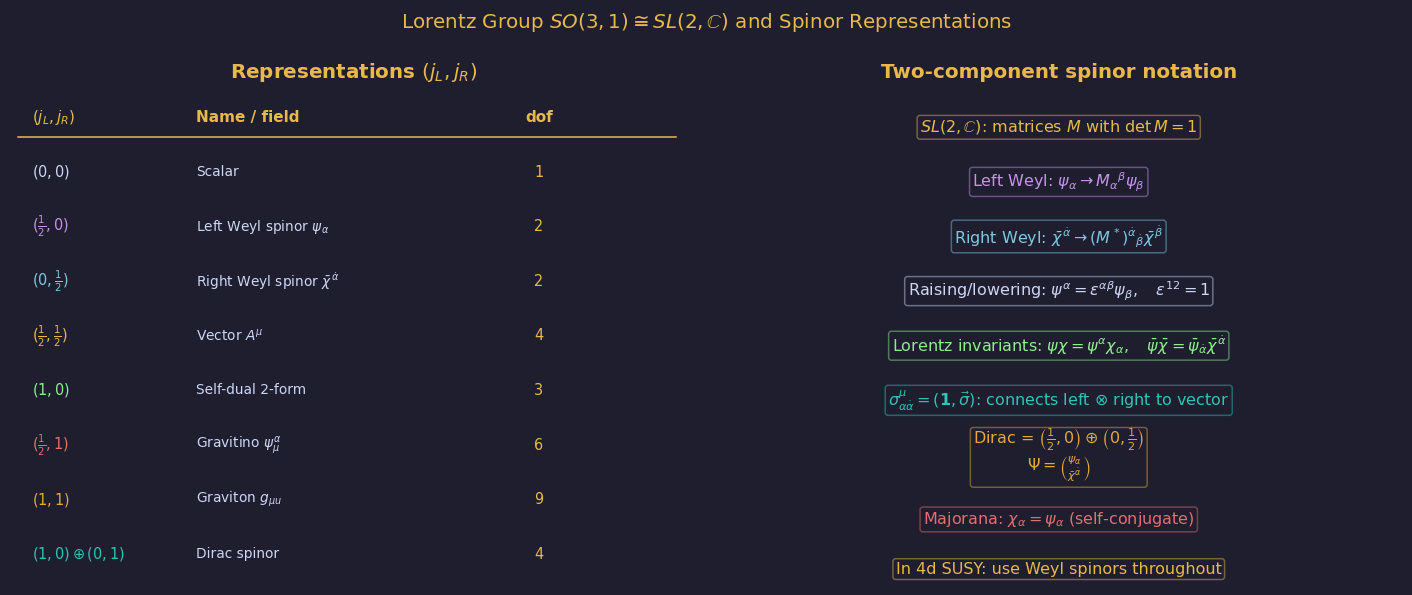

In [2]:
# ── Figure 1: Lorentz group SL(2,C) and spinor representations ─────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r'Lorentz Group $SO(3,1) \cong SL(2,\mathbb{C})$ and Spinor Representations',
             color=GOLD, fontsize=13)

# Left: representation table
ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Representations $(j_L, j_R)$', color=GOLD)

reps = [
    (r'$(0,0)$',                     'Scalar',                                    1,  FG),
    (r'$(\frac{1}{2},0)$',           r'Left Weyl spinor $\psi_\alpha$',            2,  PURP),
    (r'$(0,\frac{1}{2})$',           r'Right Weyl spinor $\bar\chi^{\dot\alpha}$', 2, BLUE),
    (r'$(\frac{1}{2},\frac{1}{2})$', r'Vector $A^\mu$',                            4,  GOLD),
    (r'$(1,0)$',                     r'Self-dual 2-form',                          3,  GREEN),
    (r'$(\frac{1}{2},1)$',           r'Gravitino $\psi_\mu^\alpha$',               6, RED),
    (r'$(1,1)$',                     r'Graviton $g_{\mu u}$',                      9, ORAN),
    (r'$(1,0)\oplus(0,1)$',          'Dirac spinor',                              4, TEAL),
]
col_xs = [0.03, 0.27, 0.75, 0.91]
headers = [r'$(j_L,j_R)$', 'Name / field', 'dof', '']
ys = np.linspace(0.94, 0.06, len(reps)+1)
for j, h in enumerate(headers):
    ax.text(col_xs[j], ys[0], h, ha='left', va='center', fontsize=10,
            color=GOLD, fontweight='bold', transform=ax.transAxes)
ax.axhline(ys[0]-0.04, xmin=0.01, xmax=0.97, color=GOLD, lw=1) #, transform=ax.transAxes)
for i, (rep, name, dof, col) in enumerate(reps):
    y = ys[i+1]
    ax.text(col_xs[0], y, rep,  ha='left', va='center', fontsize=9.5,
            color=col, transform=ax.transAxes)
    ax.text(col_xs[1], y, name, ha='left', va='center', fontsize=9,
            color=FG, transform=ax.transAxes)
    ax.text(col_xs[2]+0.02, y, str(dof), ha='center', va='center',
            fontsize=9.5, color=GOLD, transform=ax.transAxes)

# Right: spinor index notation schematic
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('Two-component spinor notation', color=GOLD)

items = [
    (0.5, 0.92, r'$SL(2,\mathbb{C})$: matrices $M$ with $\det M=1$', GOLD),
    (0.5, 0.81, r'Left Weyl: $\psi_\alpha \to M_\alpha{}^\beta \psi_\beta$', PURP),
    (0.5, 0.70, r'Right Weyl: $\bar\chi^{\dot\alpha} \to (M^*)^{\dot\alpha}{}_{\dot\beta}\bar\chi^{\dot\beta}$', BLUE),
    (0.5, 0.59, r'Raising/lowering: $\psi^\alpha = \epsilon^{\alpha\beta}\psi_\beta,\quad\epsilon^{12}=1$', FG),
    (0.5, 0.48, r'Lorentz invariants: $\psi\chi = \psi^\alpha\chi_\alpha,\quad \bar\psi\bar\chi = \bar\psi_{\dot\alpha}\bar\chi^{\dot\alpha}$', GREEN),
    (0.5, 0.37, r'$\sigma^\mu_{\alpha\dot\alpha} = (\mathbf{1}, \vec\sigma)$: connects left $\otimes$ right to vector', TEAL),
    # (0.5, 0.26, r'Dirac = $(\frac{1}{2},0)\oplus(0,\frac{1}{2}): \Psi = \begin{pmatrix}\psi_\alpha\ \bar\chi^{\dot\alpha}\end{pmatrix}$', ORAN),
    (0.5, 0.26, 'Dirac = ' + r'$\left(\frac{1}{2},0\right)\oplus\left(0,\frac{1}{2}\right)$' + '\n' + r'$\Psi = \binom{\psi_\alpha}{\bar\chi^{\dot\alpha}}$', ORAN),
    (0.5, 0.13, r'Majorana: $\chi_\alpha = \psi_\alpha$ (self-conjugate)', RED),
    (0.5, 0.03, r'In 4d SUSY: use Weyl spinors throughout', GOLD),
]
for x_, y_, txt, col in items:
    ax2.text(x_, y_, txt, ha='center', va='center', fontsize=10.5, color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.18', fc=BG, ec=col, alpha=0.45))

plt.tight_layout()
save('fig01_lorentz_spinors.png', fig)


  saved -> figures/ch02/fig02_susy_algebra.png


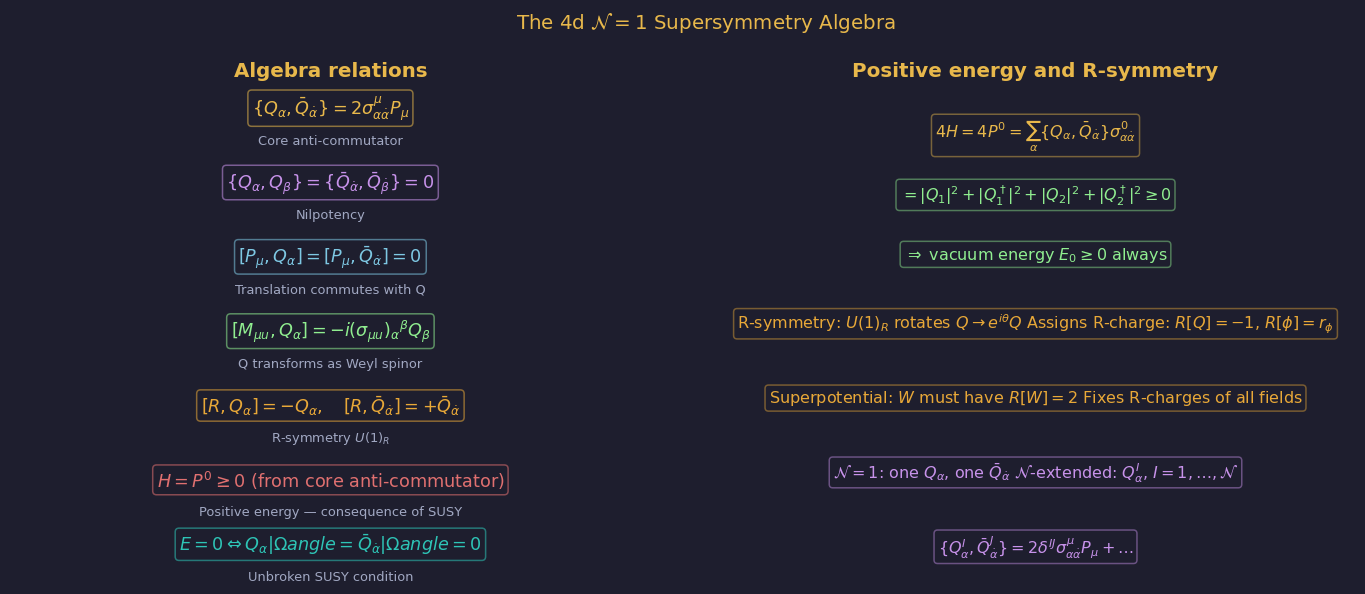

In [3]:
# ── Figure 2: SUSY algebra structure ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('The 4d $\\mathcal{N}=1$ Supersymmetry Algebra', color=GOLD, fontsize=13)

ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Algebra relations', color=GOLD)

relations = [
    (0.5, 0.93, r'$\{Q_\alpha, \bar Q_{\dot\alpha}\} = 2\sigma^\mu_{\alpha\dot\alpha} P_\mu$',
     'Core anti-commutator', GOLD),
    (0.5, 0.78, r'$\{Q_\alpha, Q_\beta\} = \{\bar Q_{\dot\alpha},\bar Q_{\dot\beta}\} = 0$',
     'Nilpotency', PURP),
    (0.5, 0.63, r'$[P_\mu, Q_\alpha] = [P_\mu, \bar Q_{\dot\alpha}] = 0$',
     'Translation commutes with Q', BLUE),
    (0.5, 0.48, r'$[M_{\mu u}, Q_\alpha] = -i(\sigma_{\mu u})_\alpha{}^\beta Q_\beta$',
     'Q transforms as Weyl spinor', GREEN),
    (0.5, 0.33, r'$[R, Q_\alpha] = -Q_\alpha,\quad [R, \bar Q_{\dot\alpha}] = +\bar Q_{\dot\alpha}$',
     'R-symmetry $U(1)_R$', ORAN),
    (0.5, 0.18, r'$H = P^0 \geq 0$ (from core anti-commutator)',
     'Positive energy — consequence of SUSY', RED),
    (0.5, 0.05, r'$E=0 \Leftrightarrow Q_\alpha|\Omega angle = \bar Q_{\dot\alpha}|\Omega angle = 0$',
     'Unbroken SUSY condition', TEAL),
]
for x_, y_, eq, desc, col in relations:
    ax.text(x_, y_+0.025, eq,   ha='center', va='center', fontsize=11.5, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.22', fc=BG, ec=col, alpha=0.55))
    ax.text(x_, y_-0.040, desc, ha='center', va='center', fontsize=8.5, color=FG,
            alpha=0.75, transform=ax.transAxes)

# Right: energy positivity proof
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('Positive energy and R-symmetry', color=GOLD)

proof_items = [
    (0.5, 0.90, r'$4H = 4P^0 = \sum_\alpha \{Q_\alpha, \bar Q_{\dot\alpha}\}\sigma^0_{\alpha\dot\alpha}$', GOLD),
    (0.5, 0.78, r'$= |Q_1|^2 + |Q_1^\dagger|^2 + |Q_2|^2 + |Q_2^\dagger|^2 \geq 0$', GREEN),
    (0.5, 0.66, r'$\Rightarrow$ vacuum energy $E_0 \geq 0$ always', GREEN),
    (0.5, 0.52,
     r'R-symmetry: $U(1)_R$ rotates $Q \to e^{i\theta}Q$' + ' ' +
     r'Assigns R-charge: $R[Q]=-1$, $R[\phi]=r_\phi$', ORAN),
    (0.5, 0.37, r'Superpotential: $W$ must have $R[W]=2$' + ' ' +
     r'Fixes R-charges of all fields', ORAN),
    (0.5, 0.22,
     r'$\mathcal{N}=1$: one $Q_\alpha$, one $\bar Q_{\dot\alpha}$' + ' ' +
     r'$\mathcal{N}$-extended: $Q^I_\alpha$, $I=1,\ldots,\mathcal{N}$', PURP),
    (0.5, 0.07, r'$\{Q^I_\alpha, \bar Q^J_{\dot\alpha}\} = 2\delta^{IJ}\sigma^\mu_{\alpha\dot\alpha}P_\mu + \ldots$', PURP),
]
for x_, y_, txt, col in proof_items:
    ax2.text(x_, y_, txt, ha='center', va='center', fontsize=10.5, color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.22', fc=BG, ec=col, alpha=0.45))

plt.tight_layout()
save('fig02_susy_algebra.png', fig)


  saved -> figures/ch02/fig03_massless_multiplets.png


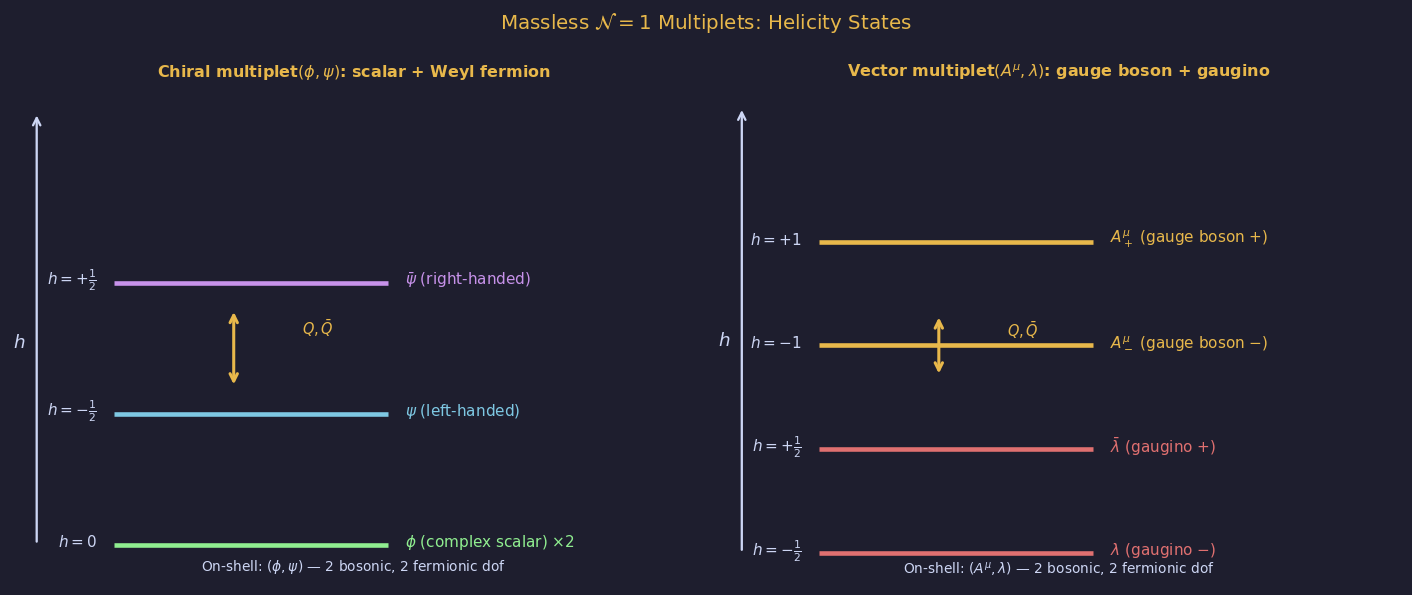

In [4]:
# ── Figure 3: Massless SUSY multiplets ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r'Massless $\mathcal{N}=1$ Multiplets: Helicity States',
             color=GOLD, fontsize=13)

def draw_multiplet(ax, title, states, col_top, col_bot):
    ax.set_facecolor(BG); ax.axis('off')
    ax.set_title(title, color=GOLD, fontsize=10.5)
    ax.set_xlim(0, 4); ax.set_ylim(-0.3, len(states)+0.5)
    ax.annotate('', xy=(0.15, len(states)+0.3), xytext=(0.15, 0),
                arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
    ax.text(0.05, (len(states))/2, r'$h$', ha='center', fontsize=12, color=FG)
    for i, (h_val, label, col, on_shell) in enumerate(states):
        y = len(states) - 1 - i
        ax.hlines(y, 0.6, 2.2, colors=col, lw=3)
        ax.text(2.3, y+0.02, label, fontsize=10, color=col, va='center')
        ax.text(0.5, y+0.02, h_val, fontsize=10, color=FG, va='center', ha='right')
    # Q arrow
    mid = len(states)/2
    ax.annotate('', xy=(1.3, mid-0.3), xytext=(1.3, mid+0.3),
                arrowprops=dict(arrowstyle='<->', color=GOLD, lw=2))
    ax.text(1.7, mid +0.15, r'$Q,\bar Q$', fontsize=9.5, color=GOLD, va='center')

ax = axes[0]
draw_multiplet(ax,
    'Chiral multiplet' + r'$(\phi, \psi)$: scalar + Weyl fermion',
    [(r'$h=+\frac{1}{2}$', r'$\bar\psi$ (right-handed)', PURP, True),
     (r'$h=-\frac{1}{2}$', r'$\psi$ (left-handed)', BLUE, True),
     (r'$h=0$',          r'$\phi$ (complex scalar) $\times 2$', GREEN, False)],
    PURP, GREEN)
ax.text(2.0, -0.2,
    r'On-shell: $(\phi,\psi)$ — 2 bosonic, 2 fermionic dof',
    ha='center', fontsize=9, color=FG)

ax2 = axes[1]
draw_multiplet(ax2,
    'Vector multiplet' + r'$(A^\mu, \lambda)$: gauge boson + gaugino',
    [(r'$h=+1$', r'$A^\mu_+$ (gauge boson $+$)', GOLD, True),
     (r'$h=-1$', r'$A^\mu_-$ (gauge boson $-$)', GOLD, True),
     (r'$h=+\frac{1}{2}$', r'$\bar\lambda$ (gaugino $+$)', RED, True),
     (r'$h=-\frac{1}{2}$', r'$\lambda$ (gaugino $-$)', RED, True)],
    GOLD, RED)
ax2.text(2.0, -0.2,
    r'On-shell: $(A^\mu,\lambda)$ — 2 bosonic, 2 fermionic dof',
    ha='center', fontsize=9, color=FG)

plt.tight_layout()
save('fig03_massless_multiplets.png', fig)


  saved -> figures/ch02/fig04_bps_multiplets.png


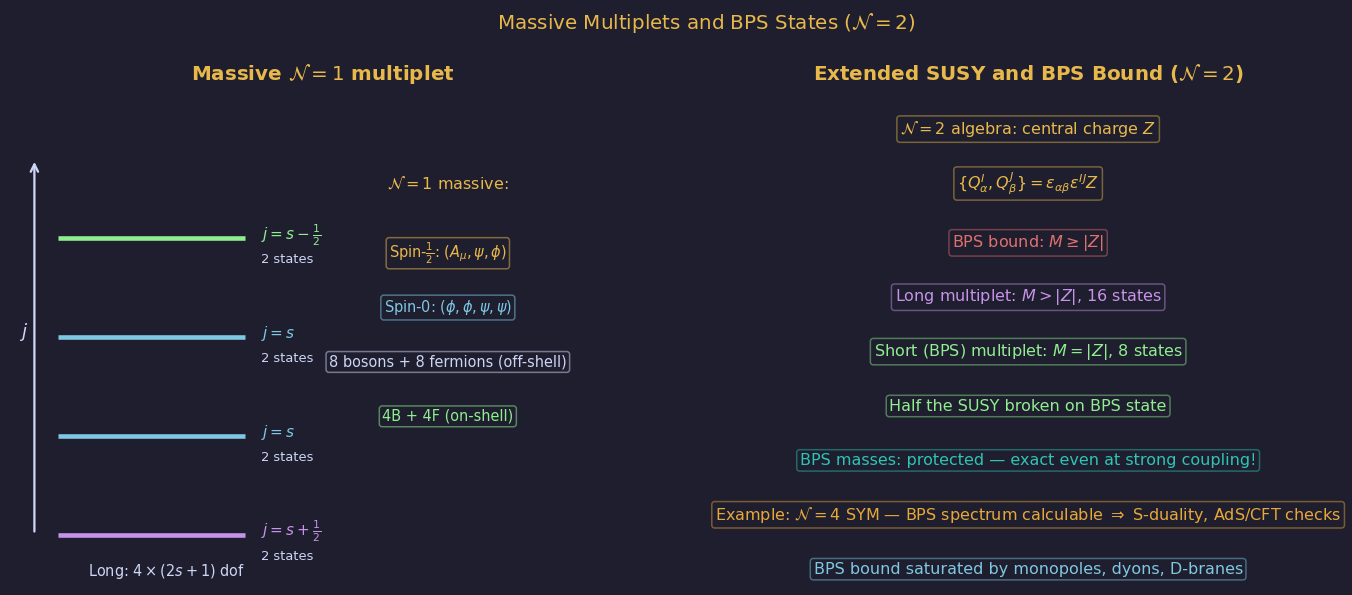

In [5]:
# ── Figure 4: Massive multiplets and BPS bound ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r'Massive Multiplets and BPS States ($\mathcal{N}=2$)',
             color=GOLD, fontsize=13)

ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r'Massive $\mathcal{N}=1$ multiplet', color=GOLD)

# Long multiplet: 4 states
states_long = [
    (r'$j=s+\frac{1}{2}$', r'2 states', PURP),
    (r'$j=s$',             r'2 states', BLUE),
    (r'$j=s$',             r'2 states', BLUE),
    (r'$j=s-\frac{1}{2}$', r'2 states', GREEN),
]
ax.set_xlim(0,4); ax.set_ylim(-0.5, 4.5)
for i, (spin, label, col) in enumerate(states_long):
    y = i
    ax.hlines(y, 0.3, 1.5, colors=col, lw=3)
    ax.text(1.6, y+0.03, spin,  fontsize=10, color=col, va='center')
    ax.text(1.6, y-0.22, label, fontsize=8.5, color=FG, va='center')

ax.text(1.0, -0.42, r'Long: $4\times(2s+1)$ dof', ha='center', fontsize=9.5, color=FG)
ax.annotate('', xy=(0.15, 3.8), xytext=(0.15, 0),
            arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
ax.text(0.08, 2, r'$j$', ha='center', fontsize=12, color=FG)

ax.text(2.8, 3.5, r'$\mathcal{N}=1$ massive:', ha='center', fontsize=10.5, color=GOLD)
simple = [
    (r'Spin-$\frac{1}{2}$: $(A_\mu,\psi,\phi)$', GOLD),
    (r'Spin-0: $(\phi, \phi, \psi, \psi)$', BLUE),
    (r'8 bosons + 8 fermions (off-shell)', FG),
    (r'4B + 4F (on-shell)', GREEN),
]
for k, (txt, col) in enumerate(simple):
    ax.text(2.8, 2.8-k*0.55, txt, ha='center', fontsize=9.5, color=col,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.5))

# Right: BPS bound
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r'Extended SUSY and BPS Bound ($\mathcal{N}=2$)', color=GOLD)

bps_items = [
    (0.5, 0.92, r'$\mathcal{N}=2$ algebra: central charge $Z$', GOLD),
    (0.5, 0.81, r'$\{Q^I_\alpha, Q^J_\beta\} = \epsilon_{\alpha\beta}\epsilon^{IJ}Z$', GOLD),
    (0.5, 0.69, r'BPS bound: $M \geq |Z|$', RED),
    (0.5, 0.58, r'Long multiplet: $M > |Z|$, $16$ states', PURP),
    (0.5, 0.47, r'Short (BPS) multiplet: $M = |Z|$, $8$ states', GREEN),
    (0.5, 0.36, r'Half the SUSY broken on BPS state', GREEN),
    (0.5, 0.25, r'BPS masses: protected — exact even at strong coupling!', TEAL),
    (0.5, 0.14,
     r'Example: $\mathcal{N}=4$ SYM — BPS spectrum calculable' + ' ' +
     r'$\Rightarrow$ S-duality, AdS/CFT checks', ORAN),
    (0.5, 0.03, r'BPS bound saturated by monopoles, dyons, D-branes', BLUE),
]
for x_, y_, txt, col in bps_items:
    ax2.text(x_, y_, txt, ha='center', va='center', fontsize=10.5, color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.45))

plt.tight_layout()
save('fig04_bps_multiplets.png', fig)


  saved -> figures/ch02/fig05_extended_susy.png


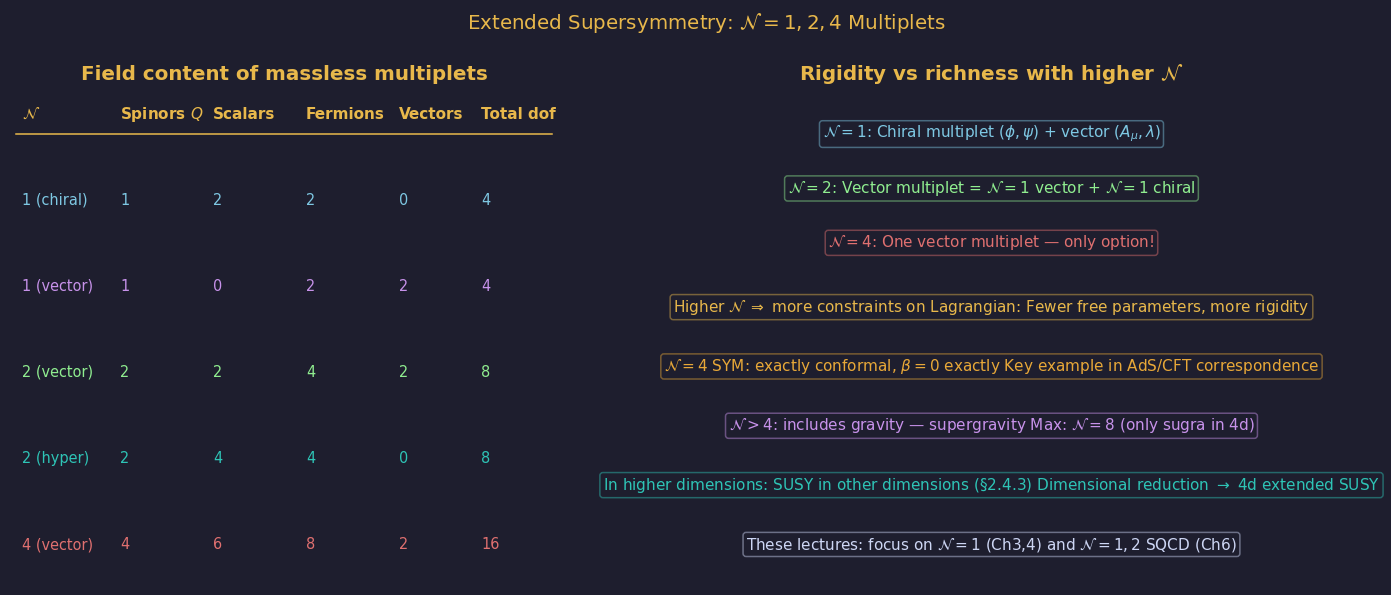

In [6]:
# ── Figure 5: Extended SUSY multiplets N=1,2,4 ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r'Extended Supersymmetry: $\mathcal{N}=1,2,4$ Multiplets',
             color=GOLD, fontsize=13)

ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r'Field content of massless multiplets', color=GOLD)

# Comparison table
rows = [
    (r'$\mathcal{N}$', 'Spinors $Q$', 'Scalars', 'Fermions', 'Vectors', 'Total dof'),
    ('1 (chiral)',  '1',  '2',  '2',  '0',  '4'),
    ('1 (vector)', '1',  '0',  '2',  '2',  '4'),
    ('2 (vector)', '2',  '2',  '4',  '2',  '8'),
    ('2 (hyper)',  '2',  '4',  '4',  '0',  '8'),
    ('4 (vector)', '4',  '6',  '8',  '2',  '16'),
]
col_xs = [0.02, 0.20, 0.37, 0.54, 0.71, 0.86]
ys_tab = np.linspace(0.95, 0.08, len(rows))
row_cols = [GOLD, BLUE, PURP, GREEN, TEAL, RED]
for i, (row, col) in enumerate(zip(rows, row_cols)):
    for j, val in enumerate(row):
        fw = 'bold' if i==0 else 'normal'
        ax.text(col_xs[j], ys_tab[i], val, ha='left', va='center',
                fontsize=9.5 if i>0 else 10, color=col, fontweight=fw,
                transform=ax.transAxes)
    if i == 0:
        ax.axhline(ys_tab[0]-0.04, xmin=0.01, xmax=0.99, color=GOLD, lw=1) #, transform=ax.transAxes)

# Right: constraint table
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r'Rigidity vs richness with higher $\mathcal{N}$', color=GOLD)

notes = [
    (0.5, 0.91, r'$\mathcal{N}=1$: Chiral multiplet $(\phi,\psi)$ + vector $(A_\mu,\lambda)$', BLUE),
    (0.5, 0.80, r'$\mathcal{N}=2$: Vector multiplet = $\mathcal{N}=1$ vector + $\mathcal{N}=1$ chiral', GREEN),
    (0.5, 0.69, r'$\mathcal{N}=4$: One vector multiplet — only option!', RED),
    (0.5, 0.56,
     r'Higher $\mathcal{N}$ $\Rightarrow$ more constraints on Lagrangian:' + ' ' +
     r'Fewer free parameters, more rigidity', GOLD),
    (0.5, 0.44,
     r'$\mathcal{N}=4$ SYM: exactly conformal, $\beta=0$ exactly' + ' ' +
     r'Key example in AdS/CFT correspondence', ORAN),
    (0.5, 0.32,
     r'$\mathcal{N}>4$: includes gravity — supergravity' + ' ' +
     r'Max: $\mathcal{N}=8$ (only sugra in 4d)', PURP),
    (0.5, 0.20,
     r'In higher dimensions: SUSY in other dimensions (§2.4.3)' + ' ' +
     r'Dimensional reduction $\to$ 4d extended SUSY', TEAL),
    (0.5, 0.08,
     r'These lectures: focus on $\mathcal{N}=1$ (Ch3,4) and $\mathcal{N}=1,2$ SQCD (Ch6)', FG),
]
for x_, y_, txt, col in notes:
    ax2.text(x_, y_, txt, ha='center', va='center', fontsize=10, color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.45))

plt.tight_layout()
save('fig05_extended_susy.png', fig)


In [7]:
import shutil
shutil.make_archive('susyft_ch02_figures', 'zip', 'figures/ch02')
try:
    from google.colab import files; files.download('susyft_ch02_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch02/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
